# KhabarNazar — Urdu-script Fake News Detection (XLM-RoBERTa)

Trains and evaluates the Urdu-script text module on three **published** datasets, kept separate:

| Dataset | Role |
|---|---|
| Hook and Bait Urdu | Main training set (E1) — with the Ax-to-Grind items removed (H&B contains them) |
| Ax-to-Grind Urdu | Second training set (E2) + cross-dataset test; length-confound check |
| UrduFake @ FIRE 2021 | Benchmark test set, official split (best published macro-F1 = 0.679) |

Bend the Truth is **not** used separately: it is already part of the FIRE 2021 training set.

**Run order:** top to bottom. Only Section 1 (paths + column names) needs editing.

## 0. Environment check
Run once in your `khabarnazar-env` venv. If `cuda` shows `False`, reinstall PyTorch with the CUDA build (see the setup notes).

In [1]:
import sys, torch
print("Python:", sys.version.split()[0])
print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0),
          "| VRAM: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

Python: 3.12.4
Torch: 2.11.0+cu128 | CUDA available: True
GPU: NVIDIA RTX A4000 | VRAM: 17.2 GB


## 1. Config — edit paths and column names here
Download the datasets into `data/raw/` (see setup notes). After running Section 2 once, check the printed column names and fix `*_TEXT_COL` / `*_LABEL_COL` if auto-detection picked the wrong ones.

In [2]:
from pathlib import Path

ROOT = Path(".")                     # folder this notebook lives in
RAW  = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
OUT  = ROOT / "outputs"
for p in (PROC, OUT): p.mkdir(parents=True, exist_ok=True)

# --- Hook and Bait (CSV/XLSX file, or a folder of them) ---
HAB_PATH       = RAW / "hook_and_bait"        # file or folder
HAB_TEXT_COL   = None                          # None = auto-detect
HAB_LABEL_COL  = None

# --- Ax-to-Grind (github.com/Sheetal83/Ax-to-Grind-Urdu-Dataset) ---
# Uses "Combined .csv" saved as Combined.csv. (The repo's "Fake News.csv" is unusable:
# its Urdu text was saved as "????".)
A2G_FILE       = RAW / "ax_to_grind" / "Combined.csv"
A2G_TEXT_COL   = None
A2G_LABEL_COL  = None

# --- FIRE 2021 UrduFake (github.com/MaazAmjad/Urdu-Fake-news-detection-FIRE2021) ---
# Train: "Training Dataset@FIRE2021" zip unzipped into data/raw/fire2021/Train
#        (its own Train/ and Test/ subfolders TOGETHER form the official 1,300-article training set)
# Test : "Test Dataset @ FIRE 2021" zip unzipped into data/raw/fire2021/Test (300 unlabeled files)
#        + Orignal_labels.xlsx (File No -> R/F) in data/raw/fire2021
FIRE_DIR         = RAW / "fire2021"
FIRE_LABELS_XLSX = FIRE_DIR / "Orignal_labels.xlsx"

SEED = 42
MODEL_NAME = "xlm-roberta-base"
MAX_LEN = 256            # try 512 (with BATCH = 8) if Hook and Bait articles are long
BATCH = 16

## 2. Loading helpers
Labels are mapped to **0 = real, 1 = fake** whatever form the source uses (`True/Fake`, `real/fake`, `1/0`, Urdu words...).

In [3]:
import pandas as pd, numpy as np, re, random, os

random.seed(SEED); np.random.seed(SEED)

TEXT_HINTS  = ["text", "news", "content", "article", "body", "headline", "title", "خبر"]
LABEL_HINTS = ["label", "class", "category", "target", "fake", "type"]

def read_any(path):
    path = Path(path)
    if path.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(path)
    for enc in ("utf-8-sig", "utf-16"):
        try:
            return pd.read_csv(path, encoding=enc)
        except (UnicodeDecodeError, UnicodeError):
            continue
    # Mostly-UTF-8 file with a few stray bytes (e.g. Ax-to-Grind "Fake News.csv"):
    # read as UTF-8, replace the broken bytes, and report how many there were.
    df = pd.read_csv(path, encoding="utf-8", encoding_errors="replace")
    txt = df.astype(str)
    bad = int(txt.apply(lambda c: c.str.count("\ufffd")).sum().sum())
    urdu = int(txt.apply(lambda c: c.str.count(r"[\u0600-\u06FF]")).sum().sum())
    if urdu and bad / urdu < 0.01:
        print(f"[{path.name}] note: replaced {bad} undecodable bytes (UTF-8 with stray bytes)")
        return df
    print(f"[{path.name}] not UTF-8, trying Windows Arabic (cp1256)")
    return pd.read_csv(path, encoding="cp1256")

def guess_col(df, hints, exclude=()):
    cols = [c for c in df.columns if c not in exclude]
    for h in hints:
        for c in cols:
            if h in str(c).lower():
                return c
    return None

def guess_text_col(df, exclude=()):
    c = guess_col(df, TEXT_HINTS, exclude)
    if c is not None: return c
    # fallback: column with the longest average string
    obj = [c for c in df.columns if df[c].dtype == object and c not in exclude]
    return max(obj, key=lambda c: df[c].astype(str).str.len().mean())

FAKE_WORDS = {"fake", "false", "1", "f", "جعلی", "جھوٹی", "غلط"}
REAL_WORDS = {"real", "true", "0", "t", "legit", "genuine", "سچ", "اصلی", "درست"}

def map_label(v):
    s = str(v).strip().lower()
    if s in FAKE_WORDS or "fake" in s: return 1
    if s in REAL_WORDS or "real" in s or "true" in s: return 0
    return np.nan

def to_std(df, text_col, label_col, source):
    out = pd.DataFrame({"text": df[text_col].astype(str),
                        "label": df[label_col].map(map_label)})
    bad = out["label"].isna().sum()
    if bad:
        print(f"[{source}] WARNING: {bad} rows had unrecognised labels:",
              df.loc[out['label'].isna(), label_col].unique()[:10])
    out = out.dropna(subset=["label"])
    out["label"] = out["label"].astype(int)
    out["source"] = source
    return out

def peek(df, name):
    print(f"\n=== {name}: {df.shape} ===")
    print("Columns:", list(df.columns))
    display(df.head(3))

### 2a. Hook and Bait

In [4]:
def label_from_name(name):
    n = name.lower()
    if "fake" in n: return 1
    if "true" in n or "real" in n: return 0
    return None

def load_hook_and_bait():
    # The GitHub release is split into several .xlsx parts named "...True News..." / "...Fake News...".
    # Each file is standardised on its own (columns can differ between parts), then all are stacked.
    p = Path(HAB_PATH)
    files = [p] if p.is_file() else sorted([*p.rglob("*.csv"), *p.rglob("*.xlsx")])
    if not files: raise FileNotFoundError(f"No CSV/XLSX found at {p}")
    parts = []
    for f in files:
        df = read_any(f)
        df = df.dropna(axis=1, how="all")
        peek(df, f"Hook and Bait — {f.name}")
        lc = HAB_LABEL_COL or guess_col(df, LABEL_HINTS)
        tc = HAB_TEXT_COL  or guess_text_col(df, exclude=[lc] if lc else [])
        fl = label_from_name(f.name)
        if fl is not None:                       # label taken from the file name
            print(f"  text col: {tc!r} | label from file name: {'fake' if fl else 'real'}")
            parts.append(pd.DataFrame({"text": df[tc].astype(str), "label": fl, "source": "hook_and_bait"}))
        elif lc is not None:
            print(f"  text col: {tc!r} | label col: {lc!r}")
            parts.append(to_std(df, tc, lc, "hook_and_bait"))
        else:
            raise ValueError(f"{f.name}: no label column and no True/Fake in the file name")
    out = pd.concat(parts, ignore_index=True)
    out = out[out["text"].str.strip().ne("") & out["text"].ne("nan")]
    return out

hab = load_hook_and_bait()
print(hab["label"].value_counts())   # README: 42,179 true / 36,230 fake


=== Hook and Bait — Fake News 12166.xlsx: (12166, 4) ===
Columns: ['Sr. No.', 'News Items', 'Label', 'Images URLs']


,Sr. No.,News Items,Label,Images URLs
0,1,میسی اور سرجیو بسکیٹس کے پیروں کو کیا گیا ہے ا...,Fake,https://www.vishvasnews.com/wp-content/uploads...
1,2,ایک دہائی پرانے ویڈیو کو کیا جا رہا مدینہ شریف...,Fake,https://www.vishvasnews.com/wp-content/uploads...
2,3,آنجہانی اداکار اوم پوری کے پرانے ویڈیو کو کلپ ...,Fake,https://www.vishvasnews.com/wp-content/uploads...


  text col: 'News Items' | label from file name: fake

=== Hook and Bait — Fake News After 12166.xlsx: (19024, 4) ===
Columns: ['Sr. No.', 'News Items', 'Label ', 'URLs']


,Sr. No.,News Items,Label,URLs
0,12167,باکو میں شوٹر تال سنگوان کے بارے میں وائرل د...,Fake,https://www.vishvasnews.com/wp-content/uploads...
1,12168,بریلی کے سینما ہال میں گیدر 2 شو کے دوران ’پ...,Fake,https://www.vishvasnews.com/wp-content/uploads...
2,12169,ایئربڈز، ائرفونز کے زیادہ استعمال کا دعویٰ چ...,Fake,https://www.vishvasnews.com/wp-content/uploads...


  text col: 'News Items' | label from file name: fake

=== Hook and Bait — Fake_News_After_31190.xlsx: (5040, 4) ===
Columns: ['Sr. No.', 'News Items', 'Label', 'Unnamed: 4']


...

  text col: 'News Items' | label from file name: real

=== Hook and Bait — True_News_after_11012.xlsx: (17466, 4) ===
Columns: ['Sr. No.', 'News Items', 'Label', 'Image URLs']


,Sr. No.,News Items,Label,Image URLs
0,11013,ایوانِ صدر نے الیکشن کمیشن کے جوابی خط پر وزار...,True,https://urdu.geo.tv/assets/uploads/updates/202...
1,11014,پاکستان اسٹاک ایکسچینج میں کاروبار کا مثبت دن,True,https://urdu.geo.tv/assets/uploads/updates/202...
2,11015,اعتماد کے ووٹ کیلئے پی ایچ ایف نے کانگریس اجلا...,True,https://urdu.geo.tv/assets/uploads/updates/202...


  text col: 'News Items' | label from file name: real

=== Hook and Bait — True_News_After_28478.xlsx: (13701, 5) ===
Columns: ['Sr. No.', 'News Items', 'Label', 'Unnamed: 3', 'Unnamed: 4']


,Sr. No.,News Items,Label,Unnamed: 3,Unnamed: 4
0,28479,دہلی میں جلد ہی مال، تجارتی علاقوں میں کھانے پ...,True,NaN,NaN
1,28480,بی جے پی مسلسل ہاردک پٹیل کو ہراساں کر رہی ہے:...,True,NaN,NaN
2,28481,کیرالہ اور پنجاب کے بعد مہاراشٹرا بھی سی اے اے...,True,NaN,NaN


  text col: 'News Items' | label from file name: real
label
0    42179
1    36230
Name: count, dtype: int64


### 2b. Ax-to-Grind

In [5]:
def load_ax_to_grind():
    df = read_any(A2G_FILE)
    df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]
    peek(df, "Ax-to-Grind Combined.csv")
    lc = A2G_LABEL_COL or guess_col(df, LABEL_HINTS)
    tc = A2G_TEXT_COL  or guess_text_col(df, exclude=[lc])
    print("Using text col:", tc, "| label col:", lc)
    return to_std(df, tc, lc, "ax_to_grind")

a2g = load_ax_to_grind()
print(a2g["label"].value_counts())   # paper: 5,030 true / 5,053 fake


=== Ax-to-Grind Combined.csv: (10106, 3) ===
Columns: ['Sr. No.', 'News Items', 'Label']


,Sr. No.,News Items,Label
0,1,ٹی ٹی پی نے پنجاب حکومت کے ہیلی کاپٹر کے عملے ...,FAKE
1,2,مارک زکربرگ سیاست میں آنے کا سوچ رہے ہیں۔,FAKE
2,3,فریدہ جلال نے اپنی موت کی افواہوں پر تنقید کی۔,FAKE


Using text col: News Items | label col: Label
[ax_to_grind] WARNING: 23 rows had unrecognised labels: <ArrowStringArray>
['Label', nan]
Length: 2, dtype: str
label
1    5053
0    5030
Name: count, dtype: int64


### 2c. FIRE 2021 (official train / test)

In [6]:
def read_text_file(f):
    raw = Path(f).read_bytes()
    for enc in ("utf-8-sig", "utf-16"):
        try: return raw.decode(enc)
        except UnicodeError: continue
    return raw.decode("utf-8", errors="replace")

def load_fire_train():
    # every file under Train/ whose path contains a Real or Fake folder
    rows = []
    for f in sorted((FIRE_DIR / "Train").rglob("*")):
        if not f.is_file(): continue
        parts = [x.lower() for x in f.parent.parts]
        lab = 1 if "fake" in parts else 0 if "real" in parts else None
        if lab is None: continue
        rows.append({"text": read_text_file(f), "label": lab, "source": "fire_train"})
    return pd.DataFrame(rows)

def load_fire_test():
    labels = pd.read_excel(FIRE_LABELS_XLSX)
    labels.columns = [str(c).strip() for c in labels.columns]
    num_col = [c for c in labels.columns if "no" in c.lower() or "file" in c.lower()][0]
    lab_col = [c for c in labels.columns if c != num_col][0]
    lab_map = {int(n): (1 if str(v).strip().upper().startswith("F") else 0)
               for n, v in zip(labels[num_col], labels[lab_col])}
    rows, unmatched = [], []
    for f in sorted((FIRE_DIR / "Test").rglob("*")):
        if not f.is_file(): continue
        nums = re.findall(r"\d+", f.stem)
        n = int(nums[-1]) if nums else None
        if n in lab_map:
            rows.append({"text": read_text_file(f), "label": lab_map[n], "source": "fire_test", "file_no": n})
        else:
            unmatched.append(f.name)
    if unmatched: print("WARNING: test files with no label:", unmatched[:10], "...", len(unmatched))
    df = pd.DataFrame(rows)
    print(f"FIRE test: matched {len(df)} of {len(lab_map)} labels")
    return df.drop(columns="file_no")

fire_train = load_fire_train()
fire_test  = load_fire_test()
print("FIRE train:", fire_train["label"].value_counts().to_dict(), "(expect 750 real / 550 fake)")
print("FIRE test :", fire_test["label"].value_counts().to_dict(),  "(expect 200 real / 100 fake)")

FIRE test: matched 300 of 300 labels
FIRE train: {0: 750, 1: 550} (expect 750 real / 550 fake)
FIRE test : {0: 200, 1: 100} (expect 200 real / 100 fake)


## 3. Cleaning
Unicode-normalises Urdu letters (Arabic ي/ك/ه variants → Urdu forms), strips URLs, emails, HTML, diacritics (aerab) and extra whitespace. Then drops empty rows and duplicates **within** and **across** datasets.

In [7]:
import unicodedata

CHAR_MAP = {
    "ي": "ی",  # Arabic yeh  -> Urdu yeh
    "ى": "ی",  # alef maksura -> Urdu yeh
    "ك": "ک",  # Arabic kaf  -> Urdu kaf
    "ه": "ہ",  # Arabic heh  -> Urdu heh goal
    "ە": "ہ",  # ae          -> heh goal
    "ة": "ۃ",  # teh marbuta -> Urdu teh marbuta goal
    "‌": " ", "‍": "", "‏": "", "‎": "",
}
DIACRITICS = re.compile(r"[ً-ْٰٖ-ٟ]")
URL   = re.compile(r"https?://\S+|www\.\S+")
EMAIL = re.compile(r"\S+@\S+")
HTML  = re.compile(r"<[^>]+>")
SPACE = re.compile(r"\s+")

def clean_urdu(t):
    t = unicodedata.normalize("NFKC", str(t))
    t = "".join(CHAR_MAP.get(ch, ch) for ch in t)
    t = DIACRITICS.sub("", t)
    t = URL.sub(" ", t); t = EMAIL.sub(" ", t); t = HTML.sub(" ", t)
    return SPACE.sub(" ", t).strip()

def dedup_key(t):
    # letters only (Unicode category "Lo"): ignores spaces, digits, punctuation (۔ ، ؟) and symbols,
    # so near-copies like "جلد ہی 24×7 مال" vs "جلد ہی مال" are caught as the same article
    return "".join(c for c in t if unicodedata.category(c) == "Lo")

def clean_df(df):
    df = df.copy()
    df["text"] = df["text"].map(clean_urdu)
    df = df[df["text"].str.split().str.len() >= 3]
    df["key"] = df["text"].map(dedup_key)
    df = df[df["key"].str.len() >= 10]
    before = len(df)
    df = df.drop_duplicates(subset="key")
    print(f"{df['source'].iloc[0]}: {before} -> {len(df)} after within-dataset dedup")
    return df.reset_index(drop=True)

hab, a2g = clean_df(hab), clean_df(a2g)
fire_train, fire_test = clean_df(fire_train), clean_df(fire_test)

# Drop any text with conflicting labels inside a dataset
for name in ["hab", "a2g", "fire_train", "fire_test"]:
    d = globals()[name]
    conflict = d.groupby("key")["label"].nunique()
    bad = set(conflict[conflict > 1].index)
    if bad: print(name, "removing", len(bad), "conflicting-label texts")
    globals()[name] = d[~d["key"].isin(bad)].reset_index(drop=True)

hook_and_bait: 78387 -> 77075 after within-dataset dedup
ax_to_grind: 10081 -> 9201 after within-dataset dedup
fire_train: 1300 -> 1291 after within-dataset dedup
fire_test: 300 -> 300 after within-dataset dedup


### Cross-dataset dedup
Anything that appears in a **test** set must not appear in any **training** set. FIRE test is held fixed, so overlaps are removed from the other datasets, never from FIRE test.

**Hook and Bait contains Ax-to-Grind.** Both come from the same authors (Harris et al.), and the Ax-to-Grind news items reappear inside Hook and Bait, sometimes slightly edited. The overlap is removed **from Hook and Bait**, so Ax-to-Grind stays a fully independent dataset for cross-dataset testing. Matching uses the letters-only key, so near-copies are caught too.

In [8]:
fire_test_keys = set(fire_test["key"])
for name in ["fire_train", "hab", "a2g"]:
    d = globals()[name]; n0 = len(d)
    globals()[name] = d[~d["key"].isin(fire_test_keys)].reset_index(drop=True)
    print(f"{name}: removed {n0 - len(globals()[name])} rows that also appear in FIRE test")

# FIRE train must not leak into the others' test sets either
fire_train_keys = set(fire_train["key"])
for name in ["hab", "a2g"]:
    d = globals()[name]; n0 = len(d)
    globals()[name] = d[~d["key"].isin(fire_train_keys)].reset_index(drop=True)
    print(f"{name}: removed {n0 - len(globals()[name])} rows that also appear in FIRE train")

# Hook and Bait ⊇ Ax-to-Grind: remove the overlap from Hook and Bait
overlap = set(hab["key"]) & set(a2g["key"])
print(f"Hook and Bait ∩ Ax-to-Grind: {len(overlap)} articles (removed from Hook and Bait)")
hab = hab[~hab["key"].isin(overlap)].reset_index(drop=True)

for n, d in [("Hook and Bait", hab), ("Ax-to-Grind", a2g), ("FIRE train", fire_train), ("FIRE test", fire_test)]:
    print(f"{n:14s} {len(d):6d} rows | real {int((d.label==0).sum()):6d} | fake {int((d.label==1).sum()):6d}")

fire_train: removed 0 rows that also appear in FIRE test
hab: removed 0 rows that also appear in FIRE test
a2g: removed 0 rows that also appear in FIRE test
hab: removed 323 rows that also appear in FIRE train
a2g: removed 324 rows that also appear in FIRE train
Hook and Bait ∩ Ax-to-Grind: 8424 articles (removed from Hook and Bait)
Hook and Bait   68328 rows | real  36404 | fake  31924
Ax-to-Grind      8877 rows | real   4593 | fake   4284
FIRE train       1291 rows | real    742 | fake    549
FIRE test         300 rows | real    200 | fake    100


## 4. Splits (stratified 80/10/10, seed 42) — saved to `data/processed/`

In [9]:
from sklearn.model_selection import train_test_split

def split_801010(df, name):
    tr, tmp = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
    va, te  = train_test_split(tmp, test_size=0.5, stratify=tmp["label"], random_state=SEED)
    for part, d in [("train", tr), ("val", va), ("test", te)]:
        d.reset_index(drop=True).to_csv(PROC / f"{name}_{part}.csv", index=False, encoding="utf-8")
    print(f"{name}: train {len(tr)} | val {len(va)} | test {len(te)}")
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

hab_tr, hab_va, hab_te = split_801010(hab, "hab")
a2g_tr, a2g_va, a2g_te = split_801010(a2g, "a2g")

# FIRE: official test untouched; carve a 10% validation set out of official train for early stopping
fire_tr, fire_va = train_test_split(fire_train, test_size=0.1, stratify=fire_train["label"], random_state=SEED)
fire_tr, fire_va = fire_tr.reset_index(drop=True), fire_va.reset_index(drop=True)
fire_tr.to_csv(PROC / "fire_train.csv", index=False, encoding="utf-8")
fire_va.to_csv(PROC / "fire_val.csv",   index=False, encoding="utf-8")
fire_test.to_csv(PROC / "fire_test.csv", index=False, encoding="utf-8")
print(f"fire: train {len(fire_tr)} | val {len(fire_va)} | test {len(fire_test)} (official)")

hab: train 54662 | val 6833 | test 6833
a2g: train 7101 | val 888 | test 888
fire: train 1161 | val 130 | test 300 (official)


In [16]:
words = ["وائرل", "دعوی", "پرانے ویڈیو", "پرانی تصویر", "گمراہ کن", "فرضی", "فیکٹ چیک", "تحقیق", "سچ", "جھوٹ"]
for w in words:
    f = hab[hab.label == 1]["text"].str.contains(w).mean() * 100
    r = hab[hab.label == 0]["text"].str.contains(w).mean() * 100
    print(f"{w:12s}  fake {f:5.1f}%   real {r:5.1f}%")

وائرل         fake   6.4%   real   1.8%
دعوی          fake   6.7%   real   0.8%
پرانے ویڈیو   fake   0.1%   real   0.0%
پرانی تصویر   fake   1.0%   real   0.0%
گمراہ کن      fake   2.8%   real   0.0%
فرضی          fake   1.4%   real   0.0%
فیکٹ چیک      fake   0.5%   real   0.0%
تحقیق         fake   0.5%   real   0.7%
سچ            fake   0.7%   real   0.3%
جھوٹ          fake   6.5%   real   0.2%


## 5. Length analysis (word count per class)

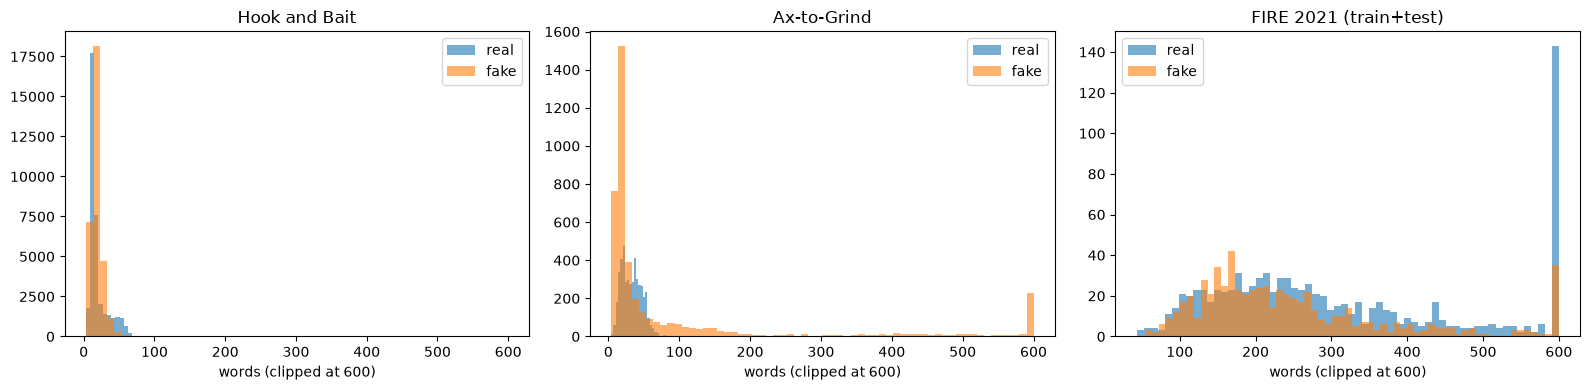

,dataset,real_mean_words,fake_mean_words,fake/real ratio,pct_over_256_tokens(approx)
0,Hook and Bait,19.7,20.0,1.01,0.3
1,Ax-to-Grind,33.5,110.1,3.29,7.0
2,FIRE train,371.2,268.7,0.72,71.9
3,FIRE test,351.5,195.2,0.56,59.3


In [10]:
import matplotlib.pyplot as plt

def wc(s): return s.str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (n, d) in zip(axes, [("Hook and Bait", hab), ("Ax-to-Grind", a2g), ("FIRE 2021 (train+test)", pd.concat([fire_train, fire_test]))]):
    for lab, name in [(0, "real"), (1, "fake")]:
        ax.hist(wc(d.loc[d.label == lab, "text"]).clip(upper=600), bins=60, alpha=0.6, label=name)
    ax.set_title(n); ax.set_xlabel("words (clipped at 600)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "length_distribution.png", dpi=150); plt.show()

stats = []
for n, d in [("Hook and Bait", hab), ("Ax-to-Grind", a2g), ("FIRE train", fire_train), ("FIRE test", fire_test)]:
    w = wc(d["text"])
    stats.append({"dataset": n,
                  "real_mean_words": round(w[d.label == 0].mean(), 1),
                  "fake_mean_words": round(w[d.label == 1].mean(), 1),
                  "fake/real ratio": round(w[d.label == 1].mean() / w[d.label == 0].mean(), 2),
                  "pct_over_256_tokens(approx)": round((w > 180).mean() * 100, 1)})
display(pd.DataFrame(stats))

## 6. Baselines
* **TF-IDF + Logistic Regression** (word 1–2 grams + char 2–5 grams)
* **Length-only classifier** — uses only word count. A high score here proves the dataset can be solved by length alone (expected on Ax-to-Grind).

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

RESULTS = []   # every experiment appends rows here

def metrics_row(model, train_name, test_name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    row = {"model": model, "trained_on": train_name, "tested_on": test_name,
           "accuracy": round(accuracy_score(y_true, y_pred), 4),
           "macro_P": round(p, 4), "macro_R": round(r, 4), "macro_F1": round(f, 4),
           "F1_fake": round(f1_score(y_true, y_pred, pos_label=1, zero_division=0), 4),
           "F1_real": round(f1_score(y_true, y_pred, pos_label=0, zero_division=0), 4)}
    RESULTS.append(row); return row

TRAIN_SETS = {"Hook and Bait": hab_tr, "Ax-to-Grind": a2g_tr, "FIRE 2021": fire_tr}
TEST_SETS  = {"Hook and Bait test": hab_te, "Ax-to-Grind test": a2g_te, "FIRE 2021 test": fire_test}

for tr_name, tr in TRAIN_SETS.items():
    # TF-IDF
    tfidf = make_pipeline(
        make_union(TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True),
                   TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, max_features=200_000, sublinear_tf=True)),
        LogisticRegression(max_iter=2000, C=4, class_weight="balanced"))
    tfidf.fit(tr["text"], tr["label"])
    # Length-only
    lenclf = LogisticRegression(class_weight="balanced")
    lenclf.fit(np.log1p(wc(tr["text"])).to_numpy().reshape(-1, 1), tr["label"])
    for te_name, te in TEST_SETS.items():
        metrics_row("TF-IDF + LR", tr_name, te_name, te["label"], tfidf.predict(te["text"]))
        metrics_row("Length-only", tr_name, te_name, te["label"],
                    lenclf.predict(np.log1p(wc(te["text"])).to_numpy().reshape(-1, 1)))

display(pd.DataFrame(RESULTS))

,model,trained_on,tested_on,accuracy,macro_P,macro_R,macro_F1,F1_fake,F1_real
0,TF-IDF + LR,Hook and Bait,Hook and Bait test,0.9574,0.9573,0.9571,0.9572,0.9543,0.9601
1,Length-only,Hook and Bait,Hook and Bait test,0.5901,0.5871,0.5852,0.5848,0.5382,0.6315
2,TF-IDF + LR,Hook and Bait,Ax-to-Grind test,0.6273,0.6303,0.6232,0.6202,0.5684,0.6720
3,Length-only,Hook and Bait,Ax-to-Grind test,0.4020,0.3665,0.4125,0.3528,0.5313,0.1742
4,TF-IDF + LR,Hook and Bait,FIRE 2021 test,0.6633,0.5827,0.5325,0.5013,0.2171,0.7856
5,Length-only,Hook and Bait,FIRE 2021 test,0.3333,0.1667,0.5000,0.2500,0.5000,0.0000
6,TF-IDF + LR,Ax-to-Grind,Hook and Bait test,0.6379,0.6453,0.6431,0.6374,0.6508,0.6241
7,Length-only,Ax-to-Grind,Hook and Bait test,0.4816,0.3835,0.4556,0.3663,0.0960,0.6366
8,TF-IDF + LR,Ax-to-Grind,Ax-to-Grind test,0.8941,0.8946,0.8935,0.8939,0.8886,0.8991
9,Length-only,Ax-to-Grind,Ax-to-Grind test,0.4696,0.4682,0.4683,0.4681,0.4400,0.4963


### Old urduhack baseline (optional)
If you saved predictions from your earlier urduhack model, add its rows here so it appears in the final table, e.g.

```python
metrics_row("urduhack (old)", "Hook and Bait", "Bend the Truth", y_true, y_pred)
```

## 7. XLM-RoBERTa fine-tuning
Hugging Face `Trainer`: lr 2e-5, 4 epochs, warmup 10 %, weight decay 0.01, fp16, early stopping on validation macro-F1 (patience 2), best checkpoint kept.
`dataloader_num_workers=0` avoids Windows multiprocessing errors inside Jupyter.

In [12]:
import torch, gc, inspect
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, EarlyStoppingCallback, DataCollatorWithPadding, set_seed)

set_seed(SEED)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator  = DataCollatorWithPadding(tokenizer)
ID2LABEL  = {0: "real", 1: "fake"}; LABEL2ID = {"real": 0, "fake": 1}

def to_hf(df):
    ds = Dataset.from_pandas(df[["text", "label"]].rename(columns={"label": "labels"}), preserve_index=False)
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["text"])

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds), "macro_f1": f1_score(labels, preds, average="macro")}

# transformers renamed evaluation_strategy -> eval_strategy; support both
_EVAL_KW = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"

def train_xlmr(train_df, val_df, run_name, init_from=MODEL_NAME, lr=2e-5, epochs=4, batch=BATCH):
    out_dir = OUT / run_name
    model = AutoModelForSequenceClassification.from_pretrained(
        init_from, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID)
    args = TrainingArguments(
        output_dir=str(out_dir),
        learning_rate=lr, num_train_epochs=epochs,
        per_device_train_batch_size=batch, per_device_eval_batch_size=batch * 2,
        warmup_steps=int(0.1 * (len(train_df) // batch + 1) * epochs), weight_decay=0.01,
        fp16=torch.cuda.is_available(),
        **{_EVAL_KW: "epoch"}, save_strategy="epoch", save_total_limit=2,
        load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
        logging_steps=50, report_to="none", seed=SEED,
        dataloader_num_workers=0)
    trainer = Trainer(model=model, args=args,
                      train_dataset=to_hf(train_df), eval_dataset=to_hf(val_df),
                      data_collator=collator, compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    trainer.train()
    best_dir = out_dir / "best"
    trainer.save_model(str(best_dir)); tokenizer.save_pretrained(str(best_dir))
    print("Saved best model to", best_dir)
    return trainer

@torch.no_grad()
def predict_df(trainer, df):
    return trainer.predict(to_hf(df)).predictions.argmax(-1)

def free_gpu():
    gc.collect(); torch.cuda.empty_cache()

W1022 16:53:02.310000 9452 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## 8. Length-matched Ax-to-Grind test subset
Pairs real and fake test articles of similar length (same word-count bin, equal numbers per bin). If a model's score drops a lot here, it was relying on length.

In [13]:
def length_matched(df, n_bins=10):
    d = df.copy(); d["wc"] = wc(d["text"])
    d["bin"] = pd.qcut(d["wc"], q=n_bins, duplicates="drop")
    parts = []
    for _, g in d.groupby("bin", observed=True):
        k = min((g.label == 0).sum(), (g.label == 1).sum())
        if k == 0: continue
        parts += [g[g.label == 0].sample(k, random_state=SEED), g[g.label == 1].sample(k, random_state=SEED)]
    if not parts:
        print("No real/fake length overlap at all — length alone separates this test set perfectly.")
        return df.iloc[0:0].copy()
    out = pd.concat(parts).drop(columns=["wc", "bin"]).reset_index(drop=True)
    print(f"Length-matched subset: {len(out)} rows | mean words real {wc(out[out.label==0].text).mean():.1f} vs fake {wc(out[out.label==1].text).mean():.1f}")
    return out

a2g_lm = length_matched(a2g_te)
TEST_SETS_XLMR = {**TEST_SETS, **({"Ax-to-Grind length-matched": a2g_lm} if len(a2g_lm) else {})}

Length-matched subset: 450 rows | mean words real 29.5 vs fake 34.9


In [14]:
# Reload saved models and re-test them (no training)
def load_trainer(path):
    m = AutoModelForSequenceClassification.from_pretrained(str(path))
    args = TrainingArguments(output_dir=str(OUT / "eval_tmp"), per_device_eval_batch_size=32,
                             fp16=torch.cuda.is_available(), report_to="none")
    return Trainer(model=m, args=args, data_collator=collator)

for run, name, trained_on, max_len in [
        ("E1_hook_and_bait", "XLM-R base",               "Hook and Bait",             256),
        ("E2_ax_to_grind",   "XLM-R base",               "Ax-to-Grind",               256),
        ("E3_hab_then_fire", "XLM-R base (H&B → FIRE)",  "Hook and Bait + FIRE 2021", 512)]:
    path = OUT / run / "best"
    if not path.exists():
        print("missing:", path); continue
    MAX_LEN = max_len
    t = load_trainer(path)
    for te_name, te in TEST_SETS_XLMR.items():
        print(metrics_row(name, trained_on, te_name, te["label"], predict_df(t, te)))
    del t; free_gpu()

e1 = load_trainer(OUT / "E1_hook_and_bait" / "best")   # Section 10 uses e1 for its plots
MAX_LEN = 512

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/6833 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Hook and Bait', 'tested_on': 'Hook and Bait test', 'accuracy': 0.9739, 'macro_P': 0.974, 'macro_R': 0.9736, 'macro_F1': 0.9738, 'F1_fake': 0.972, 'F1_real': 0.9756}


Map:   0%|          | 0/888 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Hook and Bait', 'tested_on': 'Ax-to-Grind test', 'accuracy': 0.6498, 'macro_P': 0.653, 'macro_R': 0.6517, 'macro_F1': 0.6495, 'F1_fake': 0.6601, 'F1_real': 0.6388}


...

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

{'model': 'XLM-R base (H&B → FIRE)', 'trained_on': 'Hook and Bait + FIRE 2021', 'tested_on': 'FIRE 2021 test', 'accuracy': 0.6867, 'macro_P': 0.6773, 'macro_R': 0.545, 'macro_F1': 0.5042, 'F1_fake': 0.2034, 'F1_real': 0.805}


Map:   0%|          | 0/450 [00:00<?, ? examples/s]

{'model': 'XLM-R base (H&B → FIRE)', 'trained_on': 'Hook and Bait + FIRE 2021', 'tested_on': 'Ax-to-Grind length-matched', 'accuracy': 0.6356, 'macro_P': 0.6492, 'macro_R': 0.6356, 'macro_F1': 0.627, 'F1_fake': 0.5707, 'F1_real': 0.6834}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## 9. Experiments
### E1 — train on Hook and Bait
The longest run (roughly 20–40 min per epoch on the A4000 at length 256).

In [17]:
e1 = train_xlmr(hab_tr, hab_va, "E1_hook_and_bait")
for te_name, te in TEST_SETS_XLMR.items():
    print(metrics_row("XLM-R base", "Hook and Bait", te_name, te["label"], predict_df(e1, te)))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/54662 [00:00<?, ? examples/s]

Map:   0%|          | 0/6833 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.149179,0.144173,0.960779,0.960483
2,0.150276,0.127089,0.973511,0.973377
3,0.056487,0.124037,0.977023,0.976909
4,0.037662,0.134942,0.976292,0.976161


...

{'model': 'XLM-R base', 'trained_on': 'Hook and Bait', 'tested_on': 'Ax-to-Grind test', 'accuracy': 0.6498, 'macro_P': 0.653, 'macro_R': 0.6517, 'macro_F1': 0.6495, 'F1_fake': 0.6601, 'F1_real': 0.6388}


Map:   0%|          | 0/300 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Hook and Bait', 'tested_on': 'FIRE 2021 test', 'accuracy': 0.3533, 'macro_P': 0.4911, 'macro_R': 0.4975, 'macro_F1': 0.3038, 'F1_fake': 0.4895, 'F1_real': 0.1182}


Map:   0%|          | 0/450 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Hook and Bait', 'tested_on': 'Ax-to-Grind length-matched', 'accuracy': 0.6022, 'macro_P': 0.6022, 'macro_R': 0.6022, 'macro_F1': 0.6022, 'F1_fake': 0.6031, 'F1_real': 0.6013}


### E2 — train on Ax-to-Grind

In [18]:
e2 = train_xlmr(a2g_tr, a2g_va, "E2_ax_to_grind")
for te_name, te in TEST_SETS_XLMR.items():
    print(metrics_row("XLM-R base", "Ax-to-Grind", te_name, te["label"], predict_df(e2, te)))
del e2; free_gpu()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/7101 [00:00<?, ? examples/s]

Map:   0%|          | 0/888 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.361351,0.270123,0.888514,0.887875
2,0.240932,0.293913,0.903153,0.902148
3,0.217279,0.244168,0.921171,0.920833
4,0.106686,0.323234,0.922297,0.921929


...

{'model': 'XLM-R base', 'trained_on': 'Ax-to-Grind', 'tested_on': 'Ax-to-Grind test', 'accuracy': 0.9167, 'macro_P': 0.9187, 'macro_R': 0.9155, 'macro_F1': 0.9163, 'F1_fake': 0.9108, 'F1_real': 0.9218}


Map:   0%|          | 0/300 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Ax-to-Grind', 'tested_on': 'FIRE 2021 test', 'accuracy': 0.36, 'macro_P': 0.5082, 'macro_R': 0.5025, 'macro_F1': 0.3136, 'F1_fake': 0.4921, 'F1_real': 0.1351}


Map:   0%|          | 0/450 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Ax-to-Grind', 'tested_on': 'Ax-to-Grind length-matched', 'accuracy': 0.8689, 'macro_P': 0.871, 'macro_R': 0.8689, 'macro_F1': 0.8687, 'F1_fake': 0.8637, 'F1_real': 0.8737}


### E3 — continue E1 on FIRE 2021 train, test on official FIRE test
Lower lr (1e-5), 3 epochs. Target to beat: **0.679 macro-F1**.

In [19]:
   MAX_LEN = 512
   e3 = train_xlmr(fire_tr, fire_va, "E3_hab_then_fire",
                   init_from=str(OUT / "E1_hook_and_bait" / "best"), lr=1e-5, epochs=3, batch=8)
   for te_name, te in TEST_SETS_XLMR.items():
       print(metrics_row("XLM-R base (H&B → FIRE)", "Hook and Bait + FIRE 2021", te_name, te["label"], predict_df(e3, te)))

Loading weights:   0%|          | 0/201 [00:05<?, ?it/s]

Map:   0%|          | 0/1161 [00:00<?, ? examples/s]

Map:   0%|          | 0/130 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.713343,0.658789,0.623077,0.603338
2,0.617052,0.660889,0.646154,0.604915
3,0.549549,0.674638,0.630769,0.617741


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

{'model': 'XLM-R base (H&B → FIRE)', 'trained_on': 'Hook and Bait + FIRE 2021', 'tested_on': 'Ax-to-Grind test', 'accuracy': 0.6419, 'macro_P': 0.6611, 'macro_R': 0.6348, 'macro_F1': 0.6236, 'F1_fake': 0.5405, 'F1_real': 0.7066}


Map:   0%|          | 0/300 [00:00<?, ? examples/s]

{'model': 'XLM-R base (H&B → FIRE)', 'trained_on': 'Hook and Bait + FIRE 2021', 'tested_on': 'FIRE 2021 test', 'accuracy': 0.6867, 'macro_P': 0.6773, 'macro_R': 0.545, 'macro_F1': 0.5042, 'F1_fake': 0.2034, 'F1_real': 0.805}


Map:   0%|          | 0/450 [00:00<?, ? examples/s]

{'model': 'XLM-R base (H&B → FIRE)', 'trained_on': 'Hook and Bait + FIRE 2021', 'tested_on': 'Ax-to-Grind length-matched', 'accuracy': 0.6356, 'macro_P': 0.6492, 'macro_R': 0.6356, 'macro_F1': 0.627, 'F1_fake': 0.5707, 'F1_real': 0.6834}


In [15]:
MAX_LEN = 512

# E3b — E1 model -> FIRE, stronger settings
e3b = train_xlmr(fire_tr, fire_va, "E3b_hab_then_fire",
                 init_from=str(OUT / "E1_hook_and_bait" / "best"), lr=2e-5, epochs=8, batch=8)
for te_name, te in TEST_SETS_XLMR.items():
    print(metrics_row("XLM-R (H&B → FIRE, lr2e-5 ×8)", "Hook and Bait + FIRE 2021", te_name, te["label"], predict_df(e3b, te)))
del e3b; free_gpu()

# E4 — FIRE only, from scratch
e4 = train_xlmr(fire_tr, fire_va, "E4_fire_only", lr=2e-5, epochs=8, batch=8)
for te_name, te in TEST_SETS_XLMR.items():
    print(metrics_row("XLM-R (FIRE only)", "FIRE 2021", te_name, te["label"], predict_df(e4, te)))
del e4; free_gpu()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/1161 [00:00<?, ? examples/s]

Map:   0%|          | 0/130 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.726312,0.637120,0.653846,0.611322
2,0.618625,0.680705,0.653846,0.644571
3,0.554926,0.682894,0.661538,0.617749
4,0.490573,0.984254,0.615385,0.604045


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

{'model': 'XLM-R (FIRE only)', 'trained_on': 'FIRE 2021', 'tested_on': 'Ax-to-Grind test', 'accuracy': 0.5631, 'macro_P': 0.5667, 'macro_R': 0.5558, 'macro_F1': 0.5407, 'F1_fake': 0.4393, 'F1_real': 0.6421}


Map:   0%|          | 0/300 [00:00<?, ? examples/s]

{'model': 'XLM-R (FIRE only)', 'trained_on': 'FIRE 2021', 'tested_on': 'FIRE 2021 test', 'accuracy': 0.69, 'macro_P': 0.6975, 'macro_R': 0.5475, 'macro_F1': 0.5063, 'F1_fake': 0.2051, 'F1_real': 0.8075}


Map:   0%|          | 0/450 [00:00<?, ? examples/s]

{'model': 'XLM-R (FIRE only)', 'trained_on': 'FIRE 2021', 'tested_on': 'Ax-to-Grind length-matched', 'accuracy': 0.6244, 'macro_P': 0.6343, 'macro_R': 0.6244, 'macro_F1': 0.6174, 'F1_fake': 0.5656, 'F1_real': 0.6693}


## 10. Results table + confusion matrices

In [21]:
res = pd.DataFrame(RESULTS)
res.to_csv(OUT / "results.csv", index=False)
pivot = res.pivot_table(index=["model", "trained_on"], columns="tested_on", values="macro_F1")
display(pivot.round(3))
print("Published best on FIRE 2021 test: macro-F1 0.679")

tested_on                                                Ax-to-Grind length-matched  \
model                         trained_on                                              
Length-only                   Ax-to-Grind                                       NaN   
                              FIRE 2021                                         NaN   
                              Hook and Bait                                     NaN   
TF-IDF + LR                   Ax-to-Grind                                       NaN   
                              FIRE 2021                                         NaN   
                              Hook and Bait                                     NaN   
XLM-R (FIRE only)             FIRE 2021                                       0.617   
XLM-R (H&B → FIRE, lr2e-5 ×8) Hook and Bait + FIRE 2021                       0.661   
XLM-R base                    Ax-to-Grind                                     0.869   
                              Hook and Bait                                   0.602   
XLM-R base (H&B → FIRE)       Hook and Bait + FIRE 2021                       0.627   

tested_on                                                Ax-to-Grind test  \
model                         trained_on                                    
Length-only                   Ax-to-Grind                           0.468   
                              FIRE 2021                             0.290   
                              Hook and Bait                         0.353   
TF-IDF + LR                   Ax-to-Grind                           0.894   
                              FIRE 2021                             0.532   
                              Hook and Bait                         0.620   
XLM-R (FIRE only)             FIRE 2021                             0.541   
XLM-R (H&B → FIRE, lr2e-5 ×8) Hook and Bait + FIRE 2021             0.639   
XLM-R base                    Ax-to-Grind                           0.916   
                              Hook and Bait                         0.650   
XLM-R base (H&B → FIRE)       Hook and Bait + FIRE 2021             0.624   

tested_on                                                FIRE 2021 test  \
model                         trained_on                                  
Length-only                   Ax-to-Grind                         0.250   
                              FIRE 2021                           0.566   
                              Hook and Bait                       0.250   
TF-IDF + LR                   Ax-to-Grind                         0.473   
                              FIRE 2021                           0.668   
                              Hook and Bait                       0.501   
XLM-R (FIRE only)             FIRE 2021                           0.506   
XLM-R (H&B → FIRE, lr2e-5 ×8) Hook and Bait + FIRE 2021           0.447   
XLM-R base                    Ax-to-Grind                         0.314   
                              Hook and Bait                       0.304   
XLM-R base (H&B → FIRE)       Hook and Bait + FIRE 2021           0.504   

tested_on                                                H&B test — markers removed  \
model                         trained_on                                              
Length-only                   Ax-to-Grind                                       NaN   
                              FIRE 2021                                         NaN   
                              Hook and Bait                                     NaN   
TF-IDF + LR                   Ax-to-Grind                                       NaN   
                              FIRE 2021                                         NaN   
                              Hook and Bait                                     NaN   
XLM-R (FIRE only)             FIRE 2021                                         NaN   
XLM-R (H&B → FIRE, lr2e-5 ×8) Hook and Bait + FIRE 2021                         NaN   
XLM-R base          

Published best on FIRE 2021 test: macro-F1 0.679


Map:   0%|          | 0/6833 [00:00<?, ? examples/s]

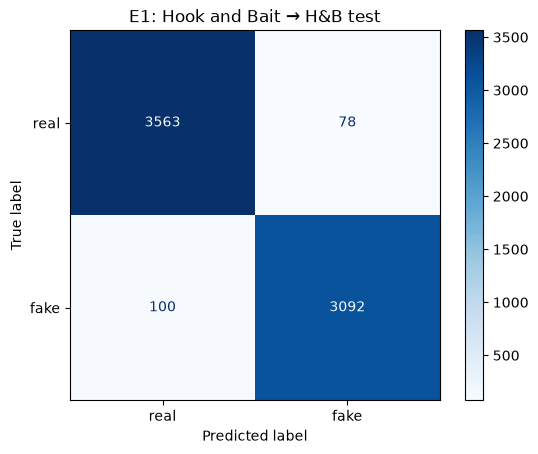

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

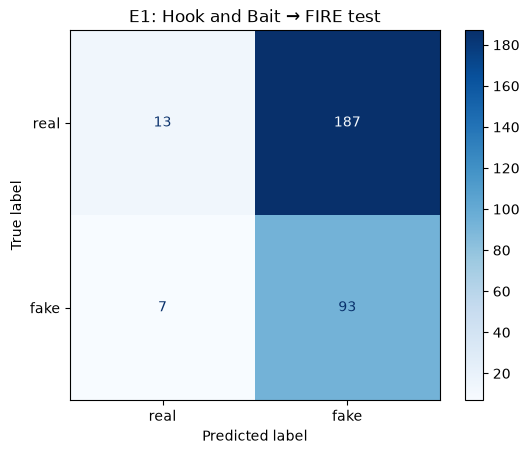

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

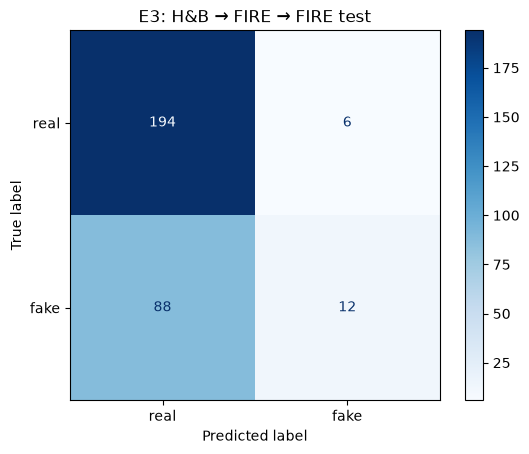

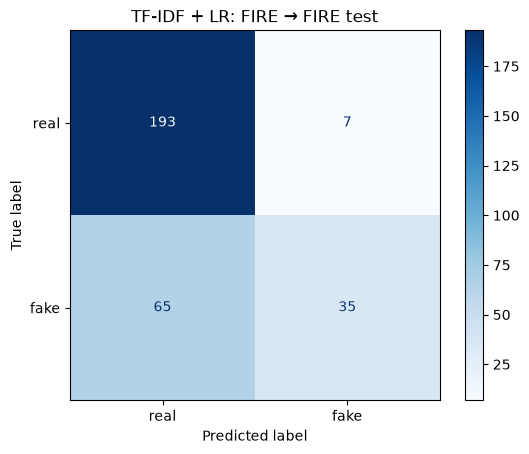

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

def plot_cm(trainer, df, title, fname):
    y = df["label"].to_numpy(); p = predict_df(trainer, df)
    ConfusionMatrixDisplay(confusion_matrix(y, p), display_labels=["real", "fake"]).plot(cmap="Blues", values_format="d")
    plt.title(title); plt.savefig(OUT / fname, dpi=150, bbox_inches="tight"); plt.show()

MAX_LEN = 256
plot_cm(e1, hab_te,    "E1: Hook and Bait → H&B test", "cm_E1_hab.png")
plot_cm(e1, fire_test, "E1: Hook and Bait → FIRE test", "cm_E1_fire.png")

MAX_LEN = 512
e3 = load_trainer(OUT / "E3_hab_then_fire" / "best")
plot_cm(e3, fire_test, "E3: H&B → FIRE → FIRE test", "cm_E3_fire.png")
del e3; free_gpu()

# TF-IDF trained on FIRE (the best FIRE model) — `tfidf` still holds the FIRE one from Section 6
ConfusionMatrixDisplay(confusion_matrix(fire_test["label"], tfidf.predict(fire_test["text"])),
                       display_labels=["real", "fake"]).plot(cmap="Blues", values_format="d")
plt.title("TF-IDF + LR: FIRE → FIRE test"); plt.savefig(OUT / "cm_tfidf_fire.png", dpi=150, bbox_inches="tight"); plt.show()

## 11. Pick final model, export, and `predict()`
Exports E1 (XLM-R trained on Hook and Bait, macro-F1 0.974) as the Urdu-script model.

In [23]:
import shutil
MAX_LEN = 256
src = OUT / "E1_hook_and_bait" / "best"
FINAL = ROOT / "urdu_text_module" / "model"
if FINAL.exists(): shutil.rmtree(FINAL)
shutil.copytree(src, FINAL)
print("Exported E1 to", FINAL.resolve())

Exported E1 to E:\KhabarNazar\urdu_text\urdu_text_module\model


In [24]:
# Standalone inference — this is what the backend will call
_tok = AutoTokenizer.from_pretrained(FINAL)
_mdl = AutoModelForSequenceClassification.from_pretrained(FINAL).eval()
_dev = "cuda" if torch.cuda.is_available() else "cpu"; _mdl.to(_dev)

@torch.no_grad()
def predict(text: str) -> dict:
    enc = _tok(clean_urdu(text), truncation=True, max_length=MAX_LEN, return_tensors="pt").to(_dev)
    probs = torch.softmax(_mdl(**enc).logits, -1)[0].cpu()
    i = int(probs.argmax())
    return {"label": _mdl.config.id2label[i], "confidence": round(float(probs[i]), 4)}

print(predict(fire_test.iloc[0]["text"]), "| true:", ID2LABEL[int(fire_test.iloc[0]['label'])])

Loading weights:   0%|          | 0/201 [00:04<?, ?it/s]

{'label': 'fake', 'confidence': 0.9693} | true: real


### Script routing for the backend
Urdu-script text → this model; Latin-letter text (Roman Urdu) → your existing Roman Urdu XLM-R model.

In [25]:
def is_urdu_script(text: str, threshold=0.5) -> bool:
    letters = [c for c in text if c.isalpha()]
    if not letters: return False
    arabic = sum("؀" <= c <= "ۿ" or "ݐ" <= c <= "ݿ" for c in letters)
    return arabic / len(letters) >= threshold

print(is_urdu_script("حکومت نے نئی پالیسی کا اعلان کیا"), is_urdu_script("hukumat ne nayi policy ka elan kiya"))

True False


In [26]:
MAX_LEN = 256
markers = ["وائرل", "دعوی", "پرانے ویڈیو", "پرانی تصویر", "گمراہ کن", "فرضی", "فیکٹ چیک", "جھوٹ", "افواہ", "غلط دعو"]
pat = "|".join(markers)

has = hab_te["text"].str.contains(pat)
print(f"H&B fakes with any marker: {hab[hab.label==1]['text'].str.contains(pat).mean()*100:.1f}%  | reals: {hab[hab.label==0]['text'].str.contains(pat).mean()*100:.1f}%")

# 1) E1 on test items WITHOUT any marker word
sub = hab_te[~has]
print(metrics_row("XLM-R base", "Hook and Bait", "H&B test — no marker words", sub["label"], predict_df(e1, sub)))

# 2) E1 on the full test set with marker words deleted from the text
masked = hab_te.copy(); masked["text"] = masked["text"].str.replace(pat, " ", regex=True)
print(metrics_row("XLM-R base", "Hook and Bait", "H&B test — markers removed", masked["label"], predict_df(e1, masked)))

H&B fakes with any marker: 18.7%  | reals: 2.9%


Map:   0%|          | 0/6119 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Hook and Bait', 'tested_on': 'H&B test — no marker words', 'accuracy': 0.9729, 'macro_P': 0.9728, 'macro_R': 0.9715, 'macro_F1': 0.9722, 'F1_fake': 0.9677, 'F1_real': 0.9766}


Map:   0%|          | 0/6833 [00:00<?, ? examples/s]

{'model': 'XLM-R base', 'trained_on': 'Hook and Bait', 'tested_on': 'H&B test — markers removed', 'accuracy': 0.9707, 'macro_P': 0.9709, 'macro_R': 0.9703, 'macro_F1': 0.9706, 'F1_fake': 0.9685, 'F1_real': 0.9727}


In [27]:
import joblib
MAX_LEN = 256

# Test 1: E1 on just the first 40 words of each FIRE article
lead = fire_test.copy(); lead["text"] = lead["text"].map(lambda t: " ".join(t.split()[:40]))
print(metrics_row("XLM-R E1 (first 40 words)", "Hook and Bait", "FIRE 2021 test — lead only", lead["label"], predict_df(e1, lead)))

# Test 2: long-article model (TF-IDF trained on all FIRE training articles), then save it
long_model = make_pipeline(
    make_union(TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True),
               TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, max_features=200_000, sublinear_tf=True)),
    LogisticRegression(max_iter=2000, C=4, class_weight="balanced")).fit(fire_train["text"], fire_train["label"])
print(metrics_row("TF-IDF (long-article model)", "FIRE 2021", "FIRE 2021 test", fire_test["label"], long_model.predict(fire_test["text"])))
joblib.dump(long_model, ROOT / "urdu_text_module" / "tfidf_long_articles.joblib")
print("saved")

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

{'model': 'XLM-R E1 (first 40 words)', 'trained_on': 'Hook and Bait', 'tested_on': 'FIRE 2021 test — lead only', 'accuracy': 0.6367, 'macro_P': 0.4744, 'macro_R': 0.4925, 'macro_F1': 0.4358, 'F1_fake': 0.0992, 'F1_real': 0.7724}
{'model': 'TF-IDF (long-article model)', 'trained_on': 'FIRE 2021', 'tested_on': 'FIRE 2021 test', 'accuracy': 0.7467, 'macro_P': 0.7841, 'macro_R': 0.635, 'macro_F1': 0.6387, 'F1_fake': 0.4412, 'F1_real': 0.8362}
saved
